In [1]:
import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import ks_2samp
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir(os.path.abspath(".."))


model = joblib.load("models/xgboost_pipeline.joblib")
df = joblib.load("data/cleaned_telco_data.joblib")

api_features = [
    "gender", "SeniorCitizen", "Partner", "Dependents", "tenure",
    "PhoneService", "MultipleLines", "InternetService", "OnlineSecurity",
    "OnlineBackup", "DeviceProtection", "TechSupport", "StreamingTV",
    "StreamingMovies", "Contract", "PaperlessBilling", "PaymentMethod",
    "MonthlyCharges", "TotalCharges"
]

X = df[api_features]
y = LabelEncoder().fit_transform(df["Churn"])


X_ref, X_prod_clean, y_ref, y_prod_clean = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Reference baseline shape:", X_ref.shape)
print("Production clean batch shape:", X_prod_clean.shape)


Reference baseline shape: (5634, 19)
Production clean batch shape: (1409, 19)


In [2]:
def calculate_psi(reference, current, bins=10):
    reference = np.asarray(reference, dtype=float)
    current = np.asarray(current, dtype=float)

    breakpoints = np.unique(np.quantile(reference, np.linspace(0, 1, bins + 1)))
    if len(breakpoints) < 2:
        return 0.0

    breakpoints[0] = -np.inf
    breakpoints[-1] = np.inf

    ref_counts, _ = np.histogram(reference, bins=breakpoints)
    cur_counts, _ = np.histogram(current, bins=breakpoints)

    ref_pct = np.where(ref_counts / len(reference) == 0, 1e-6, ref_counts / len(reference))
    cur_pct = np.where(cur_counts / len(current) == 0, 1e-6, cur_counts / len(current))

    return float(np.sum((cur_pct - ref_pct) * np.log(cur_pct / ref_pct)))

def psi_status(psi_value):
    if psi_value < 0.10:
        return "OK (No Drift)"
    elif psi_value < 0.25:
        return "WARNING (Moderate Drift)"
    return "ALERT (Severe Drift)"

print("Monitoring functions ready!")


Monitoring functions ready!


,Feature,Clean_PSI,Drifted_PSI,Status,KS_Statistic,KS_P_Value
0,tenure,0.0067,0.0067,OK (No Drift),0.0212,0.6835
1,MonthlyCharges,0.0125,2.3326,ALERT (Severe Drift),0.3279,0.0000
2,TotalCharges,0.0079,0.1024,WARNING (Moderate Drift),0.0986,0.0000


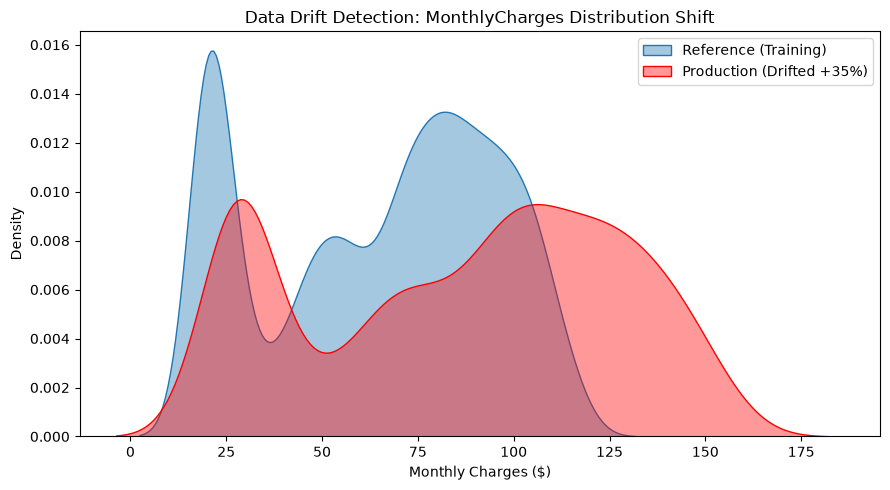

In [3]:

X_prod_drifted = X_prod_clean.copy()
X_prod_drifted["MonthlyCharges"] = X_prod_drifted["MonthlyCharges"] * 1.35
X_prod_drifted["TotalCharges"] = X_prod_drifted["TotalCharges"] * 1.35

num_cols = ["tenure", "MonthlyCharges", "TotalCharges"]
drift_report = []

for col in num_cols:
    psi_clean = calculate_psi(X_ref[col], X_prod_clean[col])
    psi_drift = calculate_psi(X_ref[col], X_prod_drifted[col])
    ks_stat, ks_pval = ks_2samp(X_ref[col], X_prod_drifted[col])

    drift_report.append({
        "Feature": col,
        "Clean_PSI": round(psi_clean, 4),
        "Drifted_PSI": round(psi_drift, 4),
        "Status": psi_status(psi_drift),
        "KS_Statistic": round(ks_stat, 4),
        "KS_P_Value": round(ks_pval, 6)
    })

drift_df = pd.DataFrame(drift_report)
display(drift_df)

plt.figure(figsize=(9, 5))
sns.kdeplot(X_ref["MonthlyCharges"], label="Reference (Training)", fill=True, alpha=0.4)
sns.kdeplot(X_prod_drifted["MonthlyCharges"], label="Production (Drifted +35%)", fill=True, alpha=0.4, color="red")
plt.title("Data Drift Detection: MonthlyCharges Distribution Shift")
plt.xlabel("Monthly Charges ($)")
plt.legend()
plt.tight_layout()
plt.show()


In [4]:

ref_probs = model.predict_proba(X_ref)[:, 1]
clean_probs = model.predict_proba(X_prod_clean)[:, 1]
drifted_probs = model.predict_proba(X_prod_drifted)[:, 1]

prob_psi_clean = calculate_psi(ref_probs, clean_probs)
prob_psi_drift = calculate_psi(ref_probs, drifted_probs)

print(f"Prediction Probability PSI (Clean Batch)  : {prob_psi_clean:.4f} -> {psi_status(prob_psi_clean)}")
print(f"Prediction Probability PSI (Drifted Batch): {prob_psi_drift:.4f} -> {psi_status(prob_psi_drift)}")


clean_preds = model.predict(X_prod_clean)
drifted_preds = model.predict(X_prod_drifted)

perf_comparison = pd.DataFrame({
    "Clean_Production": [
        accuracy_score(y_prod_clean, clean_preds),
        precision_score(y_prod_clean, clean_preds),
        recall_score(y_prod_clean, clean_preds),
        f1_score(y_prod_clean, clean_preds),
        roc_auc_score(y_prod_clean, clean_probs)
    ],
    "Drifted_Production": [
        accuracy_score(y_prod_clean, drifted_preds),
        precision_score(y_prod_clean, drifted_preds),
        recall_score(y_prod_clean, drifted_preds),
        f1_score(y_prod_clean, drifted_preds),
        roc_auc_score(y_prod_clean, drifted_probs)
    ]
}, index=["Accuracy", "Precision", "Recall", "F1-Score", "ROC-AUC"])

display(perf_comparison.round(4))


Prediction Probability PSI (Clean Batch)  : 0.0080 -> OK (No Drift)
Prediction Probability PSI (Drifted Batch): 0.0429 -> OK (No Drift)


,Clean_Production,Drifted_Production
Accuracy,0.8006,0.7956
Precision,0.6620,0.6265
Recall,0.5080,0.5695
F1-Score,0.5749,0.5966
ROC-AUC,0.8437,0.8396
